___

<div style="border: 6px solid #18453B; padding: 12px; border-radius: 5px; background:#F7FAF7; color:#1A1A1A;">
<h1 style="color:#18453B; margin-top:0;">CMSE 830 — Homework 05</h1>
<h2 style="margin-bottom:4px;">Midterm Project Readiness Check: From Analysis to Data Story</h2>
<p style="margin-bottom:0;">Fall 2026</p>
</div>

___

<div style="background:#F7FAF7; color:#1A1A1A; border:2px solid #18453B; padding:12px; border-radius:5px;">
<h2 style="color:#18453B; margin-top:0;">Student Information</h2>
<p><b>Name:</b> Renae Gizzo </p>
<p><b>Project title:</b> Seeing the Trees for the Forest: Visualzing Forest Trsucture with LiDAR</p>
<p><b>GitHub repository:</b> https://github.com/rgizzo/weblidar-forest-structure </p>
<p><b>Streamlit app:</b> LINK or “local only for now”</p>
<p><b>Preliminary slide file:</b> FILE NAME / LINK</p>
</div>

## Purpose of Homework 05

This homework is a **structured midterm-project readiness check**.

Rather than simply reporting that your project is “in progress,” you will produce evidence for the major areas that will be evaluated in the midterm project:

- problem, audience, and narrative;
- data quality and preparation;
- exploratory analysis and visualization;
- interpretation and limitations;
- Streamlit interaction and usability;
- GitHub organization and reproducibility;
- presentation readiness.

The goal is to identify what is already working, what evidence supports your current conclusions, and what still needs to be completed before the midterm presentation.

> **Central principle:** Build a purposeful data product, not a checklist of techniques. If a method is not appropriate for your project, explain why rather than forcing it into the analysis.

<div style="background:#EEF5FF; color:#1A1A1A; border-left:5px solid #356AA0; padding:12px 16px; margin:12px 0;">
<h3 style="margin-top:0;">Homework 05 = 50 points</h3>
<p><b>Primary submission:</b> completed Jupyter notebook.</p>
<p><b>Companion submission:</b> preliminary presentation slides (PDF or PPTX), approximately 4–6 slides.</p>
<p>This homework should move your actual midterm project forward. Use your own project data, code, visualizations, and current Streamlit application wherever possible.</p>
</div>

## Generative AI Use

AI may support coding, debugging, documentation, interface development, and exploration of implementation alternatives when disclosed.

You remain responsible for the project question, data decisions, visualization choices, validation, interpretation, conclusions, and explaining all submitted code and analytical choices.

At the end of this notebook, include an AI-use disclosure identifying the tool/version, representative prompts or purposes, how outputs were checked, and your own contribution. If no AI was used, state that.

---
# Part 1 — Project Abstract and Focus (6 points)

A strong midterm project should be understandable to someone who has not followed your work all semester.

### 1.1 Project abstract — 4 points

Write a **150–200 word abstract** that answers:

1. What problem, question, or user need does the project address?
2. Who is the intended audience or user?
3. What data are you using?
4. What is the main analytical goal?
5. What should a user learn, compare, decide, or explore through your Streamlit app?
6. What is one important limitation or boundary of the project?

Write this as a coherent abstract rather than six separate answers.

**Your abstract:**

Forest structure is a fundamnetal characteristic of plant communities and plays an essential role is ecosystem functions. Advances in light detection and ranging (LiDAR) technologies have greatly facilitated the retrieval of forest structural complexity measurements across multiple dimensions, establishing it as a powerful tool for large scale ecosystem assessment. However, visualizing and working with raw LiDAR data is both computationally intensive and technically challenging. _Seeing the Trees for the Forest: Visualizing Forest Structure with LiDAR_ is a stream-lit based application that is deisgned to strucutral information more accessible to users from ecologists to ecosytem modelers. Using airborne LiDAR data from the National Ecological Observatory Network (NEON), the app allows users to explore three distinct forested ecosystems. The users can visualize three-dimensional point clouds, filter vegetation by height, explore how structure effects LiDAR return denisty distribution using relative height metrics (RH25, RH50, RH98). The primary analytical gaol is exploratory copmparison of forest structure across divserse ecosystems. One limitation of the app is it operates with only metrics that do not need field data calibration. 

### 1.2 Project focus — 2 points

Complete both statements:

**1.2.1 Primary analytical question:**  
> How do LiDAR-derived forets structure measurements vary between landscapes with diffrent vegetation types and climatic conditions?

**1.2.2 Intended user/action:**  
> A user should be able to use my app to vizualize point clouds in 3D and understand how metrics derived from LiDAR return-density distributions vary between forests that vary in vegetation types and climate. 

Then answer in 1–2 sentences:

**1.2.3 What is outside the scope of your midterm project but could become a meaningful extension for the final project?** 

Review the remaining course topics on D2L and identify one or two techniques, analyses, or product features that may strengthen your project later. Briefly explain why they are better suited for the final project than the midterm.

Possible extensions might include things like:
- adding a predictive or classification model;
- evaluating model performance;
- comparing multiple models;
- adding more advanced feature engineering;
- adding dimensionality reduction or clustering;
- integrating an additional dataset;
- adding richer Streamlit interactions;
- adding validation or robustness analysis;
- adding an LLM component where appropriate;
- improving deployment, user experience, or reproducibility.


**Your response:**
A meaningful addition to the midterm project would be more advanced feature engineering. It would be cool to do voxel-based metrics on a 1x1m grid and have the app show the resulsting rasters. I think plant area denisty would be fun to add, or 'gap' related metrics that focus on the openess of a canopy. Also adding more information on what the metrics mean.  

---
# Part 2 — Data Readiness and Quality (10 points)

Before adding more analysis, demonstrate that you understand the data you are building the project around.

Use **N/A with justification** when a rubric item is not relevant. You are not expected to manufacture missingness, imbalance, transformations, or other issues that do not exist.

### 2.1 Data source and observation unit — 2 points

Report:

- data source(s);
- how the data were obtained;
- what one row/observation represents;
- current number of rows and columns;
- any data-integration step, if applicable.

**Your response:**
Data source: The National Ecological Observatory Network: https://data.neonscience.org/data-products/DP1.30003.001
The data were obtained by airborne LiDAR collection in years 2025-2026.
One observtaion reperesents the X,Y,Z location of a LiDAR return. 
There are 79144 points. 
No data integration required.

In [2]:
import laspy
from pyproj import CRS

las = laspy.read("data/BART_cropped.laz")
print("Data dimensions:", list(las.point_format.dimension_names))
print("Point count:", las.header.point_count)
print("Point format:", las.header.point_format)
epsg = las.header.parse_crs().to_epsg()
print("Coordinate reference system:", epsg)
print("Min bounds [X,Y,Z]:", las.header.mins)
print("Max bounds [X,Y,Z]:", las.header.maxs)

Data dimensions: ['X', 'Y', 'Z', 'intensity', 'return_number', 'number_of_returns', 'synthetic', 'key_point', 'withheld', 'overlap', 'scanner_channel', 'scan_direction_flag', 'edge_of_flight_line', 'classification', 'user_data', 'scan_angle', 'point_source_id', 'gps_time', 'red', 'green', 'blue', 'Amp', 'Dev', 'MTA']
Point count: 79144
Point format: <PointFormat(7, 5 bytes of extra dims)>
Coordinate reference system: 32619
Min bounds [X,Y,Z]: [ 3.190e+05  4.881e+06 -1.700e-01]
Max bounds [X,Y,Z]: [3.19049990e+05 4.88104999e+06 2.23200000e+01]


### 2.2 Variable and data-type audit — 2 points

Create a compact table containing the variables most important to your project.

For most projects, focus on approximately **5–10 key variables** rather than listing every column in a wide dataset.

Include:

- variable name;
- role in the project;
- data type;
- quantitative / categorical / datetime / text / other;
- whether any transformation or encoding is currently needed.

Focus on variables that matter for the current data story.

In [3]:
# Create/display your variable audit here.
# A pandas DataFrame is a convenient format.

import pandas as pd
import numpy as np

las_df = pd.DataFrame({
    "X": np.asarray(las.x),
    "Y": np.asarray(las.y),
    "Z": np.asarray(las.z),
    "Classification": las.classification,
    "Intensity": las.intensity,
    "red": las.red,
    "green": las.green,
    "blue": las.blue,
    "Return_number": np.asarray(las.return_number)
})

las_df.head()

,X,Y,Z,Classification,Intensity,red,green,blue,Return_number
0,319000.61,4881000.56,15.66,5,10827,35072,35328,20480,1
1,319000.34,4881000.55,15.81,5,11440,28928,29184,18688,1
2,319000.99,4881000.14,15.04,5,2004,32000,31488,15104,2
3,319000.56,4881000.17,16.19,5,13806,41472,40448,22272,1
4,319000.25,4881000.13,16.05,5,5073,41728,40704,22784,1


### 2.3 Data-quality evidence — 4 points

Assess the issues below **where relevant**:

- missing values;
- duplicates;
- impossible or suspicious values;
- inconsistent categories/labels;
- extreme values/outliers;
- class imbalance, if your project has a categorical outcome;
- data-integration inconsistencies, if using multiple sources.

Show code/output for the checks you actually performed.

Then summarize the **2–3 most important data-quality decisions** you have made so far.

In [18]:
# Summary statistics
print(las_df.describe())

# Count noise points (classification 7)
print("Number of noise points:", las_df[las_df["Classification"] == 7].sum())

# Count points above 40 m
print("Points above 40m:", las_df[las_df["Z"] > 40].sum())


                   X             Y             Z  Classification  \
count   79144.000000  7.914400e+04  79144.000000    79144.000000   
mean   319025.330185  4.881026e+06     12.416179        4.618973   
std        14.277093  1.427676e+01      6.172755        1.011475   
min    319000.000000  4.881000e+06     -0.170000        1.000000   
25%    319013.320000  4.881014e+06      9.130000        5.000000   
50%    319025.080000  4.881027e+06     14.210000        5.000000   
75%    319037.710000  4.881039e+06     17.080000        5.000000   
max    319049.990000  4.881050e+06     22.320000        5.000000   

          Intensity           red         green          blue  Return_number  
count  79144.000000  79144.000000  79144.000000  79144.000000   79144.000000  
mean    6980.782308  32318.670575  30415.280299  22743.667644       1.702542  
std     4906.432283  13358.935583  10772.657030   7286.909778       0.849631  
min      906.000000   2816.000000   3072.000000   2560.000000       1.0

**Data-quality decisions and justification:**

1. The data was cropped from 1x1km to 50x50m.
2. The point clouds were normalized so the ground elevation = 0. 
3. Noise points were removed. 

### 2.4 Missingness / imputation decision — 2 points

Choose the statement that best matches your project and explain why:

- **A.** Missingness is negligible or not relevant to my current analysis.
- **B.** I will use complete-case analysis for a specific part of the project.
- **C.** I will impute one or more variables.
- **D.** Missingness is substantial and requires a more careful strategy before the midterm.
- **E.** Other.

If you impute, explain **what information the imputation uses** and what may be distorted. If you do not impute, explain why that is defensible.

**Your response:**
Missingness is not relevant to my current analysis.

---
# Part 3 — Purposeful EDA and Preliminary Evidence (12 points)

The midterm is an **interactive data story**, not a collection of unrelated plots.

Define project-specific questions first, then create evidence that addresses those questions.

### 3.1 Analytical Question 1 — 5 points

State one focused question that matters to your project.

**Question 1:**  
> What is the relative height at which 50% of the LiDAR point returns occur (RH50)?

Then provide:

1. one purposeful visualization;
2. at least one quantitative/statistical summary supporting the visual evidence;
3. a 3–5 sentence interpretation;
4. one limitation or alternative explanation.

Your interpretation should answer the question rather than merely describe the axes.

Point denisty per 1m vertical height: height_bin
[0, 1)      0.072378
[1, 2)      0.004666
[2, 3)      0.008746
[3, 4)      0.010679
[4, 5)      0.012105
[5, 6)      0.014692
[6, 7)      0.023437
[7, 8)      0.026877
[8, 9)      0.030050
[9, 10)     0.042262
[10, 11)    0.048408
[11, 12)    0.045661
[12, 13)    0.052780
[13, 14)    0.064952
[14, 15)    0.078271
[15, 16)    0.097335
[16, 17)    0.094642
[17, 18)    0.097868
[18, 19)    0.074898
[19, 20)    0.043701
[20, 21)    0.034663
[21, 22)    0.017371
[22, 23)    0.003560
Name: proportion, dtype: float64
RH50: 14.21 m


C:\Users\renae\AppData\Local\Temp\ipykernel_38832\1218374842.py:5: UserWarning: 

The `bw` parameter is deprecated in favor of `bw_method` and `bw_adjust`.
Setting `bw_method=0.1`, but please see the docs for the new parameters
and update your code. This will become an error in seaborn v0.14.0.

  sns.kdeplot(data = las_df, y = np.array(las_df['Z']), bw=0.1)


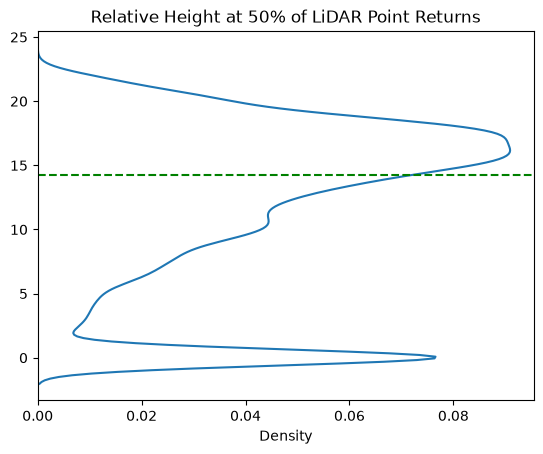

In [ ]:
# Question 1 analysis and visualization
# Full point cloud heights
import seaborn as sns
import matplotlib.pyplot as plt
sns.kdeplot(data = las_df, y = np.array(las_df['Z']), bw=0.1)
plt.axhline(y = las_df["Z"].quantile(0.50), color='green', linestyle='--', label = 'RH50')
plt.title("Relative Height at 50% of LiDAR Point Returns")
plt.legend()

# calculate denisty for 1m bins
max_height = int(las_df['Z'].max() + 1)
bins = range(0, max_height + 1)
las_df['height_bin'] = pd.cut(las_df['Z'], bins = bins, right=False)
density = las_df['height_bin'].value_counts(normalize=True).sort_index()
print("Point denisty per 1m vertical height:", density)

# calculate rh50
rh50 = las_df["Z"].quantile(0.50)
print(f"RH50: {rh50:.2f} m")

**Question 1 interpretation and limitation:**
Relative height at 50% represnets the height at which 50% of the cumulative energy is returned to the LiDAR sensor. This is helpful to describe the vertical distribution of biomass. For the point cloud used, which is from an old growth deciduious forest and has a 50x50m horizontal reoslution, the RH50 is 14.21 meters. One limitation is these metrics are traditionally calculated with full waveform LiDAR, so this isn't exactly representative of the full amount of energy returned since point clouds are descretized, but rather the height at which 50% of the points are returned. 

### 3.2 Analytical Question 2 — 5 points

State a second question that reveals a different aspect of the project.

**Question 2:**  
> What is the relative height at which 98% of the LiDAR point returns occur (RH98)?

Again provide:

1. one purposeful visualization;
2. at least one quantitative/statistical summary;
3. a 3–5 sentence interpretation;
4. one limitation or alternative explanation.

Point denisty per 1m vertical height: height_bin
[0, 1)      0.072378
[1, 2)      0.004666
[2, 3)      0.008746
[3, 4)      0.010679
[4, 5)      0.012105
[5, 6)      0.014692
[6, 7)      0.023437
[7, 8)      0.026877
[8, 9)      0.030050
[9, 10)     0.042262
[10, 11)    0.048408
[11, 12)    0.045661
[12, 13)    0.052780
[13, 14)    0.064952
[14, 15)    0.078271
[15, 16)    0.097335
[16, 17)    0.094642
[17, 18)    0.097868
[18, 19)    0.074898
[19, 20)    0.043701
[20, 21)    0.034663
[21, 22)    0.017371
[22, 23)    0.003560
Name: proportion, dtype: float64
RH98: 20.98 m


C:\Users\renae\AppData\Local\Temp\ipykernel_38832\2506332816.py:4: UserWarning: 

The `bw` parameter is deprecated in favor of `bw_method` and `bw_adjust`.
Setting `bw_method=0.1`, but please see the docs for the new parameters
and update your code. This will become an error in seaborn v0.14.0.

  sns.kdeplot(data = las_df, y = np.array(las_df['Z']), bw=0.1)


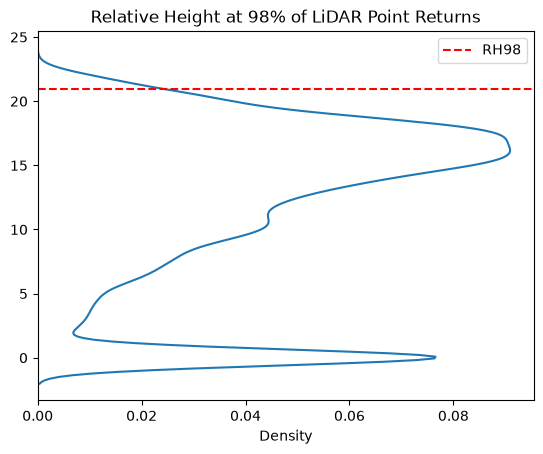

In [17]:
# Question 2 analysis and visualization
import seaborn as sns
import matplotlib.pyplot as plt
sns.kdeplot(data = las_df, y = np.array(las_df['Z']), bw=0.1)
plt.axhline(y = las_df["Z"].quantile(0.98), color='red', linestyle='--', label = 'RH98')
plt.title("Relative Height at 98% of LiDAR Point Returns")
plt.legend()

# calculate denisty for 1m bins
max_height = int(las_df['Z'].max() + 1)
bins = range(0, max_height + 1)
las_df['height_bin'] = pd.cut(las_df['Z'], bins = bins, right=False)
density = las_df['height_bin'].value_counts(normalize=True).sort_index()
print("Point denisty per 1m vertical height:", density)

# calculate rh50
rh50 = las_df["Z"].quantile(0.98)
print(f"RH98: {rh50:.2f} m")

**Question 2 interpretation and limitation:**

Relative height at 98% represents the height at which 98% of the cumulative energy is returned to the LiDAR sensor. This is equivalent to maximum canopy height for the given plot. For the point cloud used, which is 50x50m, the RH98 is 20.98m. One limitation the resolution. Not all trees within the plot have the same max height, so this is a much coarser summary than if you used metrics that are calculated for individual trees, or at a finer horizontal resolution (1x1m). 

### 3.3 Visualization design check — 2 points

Choose your **most important current visualization** and evaluate it against the following:

- Is the plot type appropriate for the variables and question?
- Are scales and axes accurate?
- Are labels understandable to a new user?
- Is color purposeful and accessible?
- Is there unnecessary clutter or redundant encoding?
- Would interaction improve the user's ability to compare or explore?

State **one concrete revision** you made or will make.

**Your response:**

Both the visuals are equally important. The plot types are apparopriate and I think they communicate the visual well. I will need to rewrite the code to make the plots inetractive becasue I plan to have a slider to decrease heights and multiple point clouds the user can look at. 

---
# Part 4 — Course Concepts: Relevance Audit and Application (8 points)

You have now encountered several analytical ideas in the course. The goal is **not** to use every method.

This section is meant to help you connect your project work to course concepts.

> **You do not need to create two completely new analyses for Part 4.**  
> You may build on analyses from Part 3 if they are relevant. The goal here is to explain why a course concept is appropriate, how you applied it, and what decision or insight it supports.

For each topic below, decide whether it is relevant to your project **at this stage**.

| Course concept | Relevant now? | Evidence / justification |
|---|---|---|
| Data types / summary statistics | Yes | The main metrics I am usng (RH) are summary statistics.|
| Missingness / imputation | No | It's not relevant to the analysis I am doing. |
| Distribution / histogram / KDE | Yes| The metrics I am using are denisty metrics.|
| Color / visual encoding / accessibility | Yes | I will have point clouds for the user to look at and have options to switch through colored by hieght, classfication, or RGB. |
| Imbalanced data |No | It's okay for the classes to be imbalanced. |
| Covariance / correlation | No | I am not doing any analysis where this is a concern because all my metrics are density based. |
| Linear regression | No | I will not be using any linear regression. |
| Transformation / feature engineering | Yes | The point clouds are normalized and cropped.|

Replace the blank cells with your project-specific assessment.

### 4.1 Apply two relevant course concepts — 6 points

Choose **two concepts** from the table that are genuinely useful for your project.

For each concept:

1. explain why it is relevant;
2. show the analysis, design check, or evidence;
3. explain what you learned;
4. state whether it changes or supports a project decision.

You may reuse a Part 3 analysis if appropriate, but add a clear course-concept interpretation rather than simply repeating the same explanation.

#### Concept A

**Chosen concept:** KDE plots

C:\Users\renae\AppData\Local\Temp\ipykernel_38832\2646423825.py:4: UserWarning: 

The `bw` parameter is deprecated in favor of `bw_method` and `bw_adjust`.
Setting `bw_method=0.1`, but please see the docs for the new parameters
and update your code. This will become an error in seaborn v0.14.0.

  sns.kdeplot(data = las_df, y = np.array(las_df['Z']), bw=0.1)


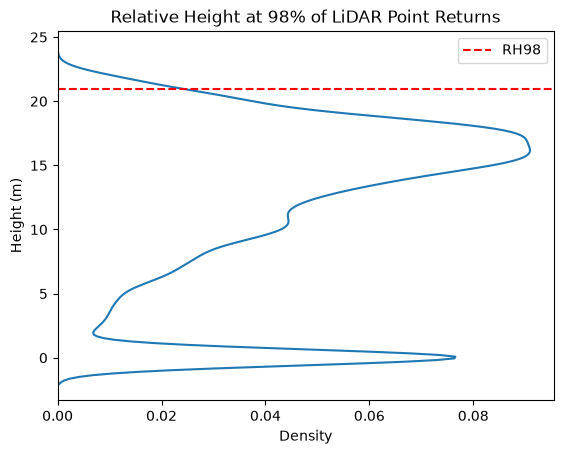

In [50]:
# Concept A analysis
import seaborn as sns
import matplotlib.pyplot as plt
sns.kdeplot(data = las_df, y = np.array(las_df['Z']), bw=0.1)
plt.axhline(y = las_df["Z"].quantile(0.98), color='red', linestyle='--', label = 'RH98')
plt.ylabel("Height (m)")
plt.title("Relative Height at 98% of LiDAR Point Returns")
plt.legend()

**Concept A interpretation / decision:**

The KDE plots are relevant becasue they represent the denisty of the point returns at each height. I will use these plots in my app because I think it is very clear to the user what RH represents when the RH line overlays the KDE plot. I learned that KDE is basically a psuedo-waveform. 

#### Concept B

**Chosen concept:** Color and visual encoding

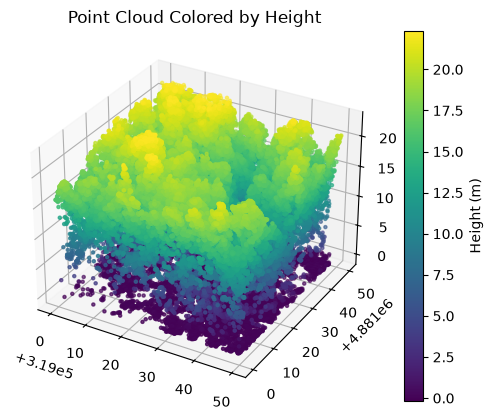

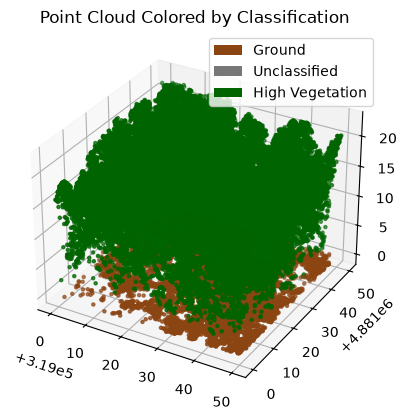

In [49]:
import numpy as np
import laspy
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# copy points
las = laspy.read("data/BART_cropped.laz")
point_records = las.points.copy()

# getting scaling and offset parameters
las_scaleX = las.header.scale[0]
las_offsetX = las.header.offset[0]
las_scaleY = las.header.scale[1]
las_offsetY = las.header.offset[1]
las_scaleZ = las.header.scale[2]
las_offsetZ = las.header.offset[2]

# calculating coordinates
p_X = np.array((point_records['X'] * las_scaleX) + las_offsetX)
p_Y = np.array((point_records['Y'] * las_scaleY) + las_offsetY)
p_Z = np.array((point_records['Z'] * las_scaleZ) + las_offsetZ)

# plotting points
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(p_X, p_Y, p_Z, c=p_Z, cmap='viridis', marker='.')
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('Height (m)')

plt.title('Point Cloud Colored by Height')
plt.show()


# color by classification 
classification = np.asarray(las.classification)

idx = np.arange(len(p_X))
    
p_X = p_X[idx]
p_Y = p_Y[idx]
p_Z = p_Z[idx]

classification = classification[idx]

colors = ("#8B4513","#777777", "#006400")
custom_cmap = ListedColormap(colors)

# plotting points
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(p_X, p_Y, p_Z, c=classification, cmap = custom_cmap, marker='.')
# Custom legend
legend_elements = [
    Patch(facecolor="#8B4513", label="Ground"),
    Patch(facecolor="#777777", label="Unclassified"),
    Patch(facecolor="#006400", label="High Vegetation")
]

ax.legend(handles=legend_elements, loc="upper right")

plt.title('Point Cloud Colored by Classification')
plt.show()


**Concept B interpretation / decision:**

I will use both of these color concepts for my app. I think its cool to visualize the point clouds in both ways, and each version is visualized with the proper color concept. I will also make these plots interactive for the app. I think it's useful to see both the discrete categories of returns and the height gradient. 

### 4.2 One concept you intentionally did NOT apply — 2 points

Choose one course concept that would be inappropriate, unnecessary, or premature for your project.

Explain why **not using it is the better analytical decision**.

**Your response:**

I did not do missing data imputation for this analysis. This is appropriate because I am doing point based metrics across the entire 50x50km chunk, so that kind of interpolation isn't necessary at this point. If I end up adding grid-based metrics for the final project, I will likely use KNN to fill in any missing ground returns. Ground returns are required when calculating metrics using a voxel column. 

---
# Part 5 — Initial Streamlit Prototype and Reproducibility Check (5 points)

We have not yet covered all of Streamlit in detail. For this homework, the goal is **not** to build a polished or sophisticated application. Instead, create a small working prototype and use it to begin turning your analysis into an interactive data story.

You may use generative AI to help you learn Streamlit syntax, debug code, or explore interface options. However, you remain responsible for understanding the code you submit and being able to explain what it does.

A strong prototype is simple, purposeful, and connected to your project question.

### 5.1 First Streamlit prototype — 3 points

Create or continue a **minimal Streamlit prototype** for your project.

At this stage, your prototype should include:

- a project title and short description of its purpose;
- at least one meaningful visualization, table, or preliminary result from your project;
- at least one simple interactive control, **when interaction is useful**, such as a `selectbox`, `multiselect`, `slider`, checkbox, or similar element;
- a clear connection between the interaction and something the user can explore, compare, or learn.

Your app only needs to run **locally** for this homework. Deployment is not required.

> **A simple app that runs and communicates one useful result is sufficient for HW05.**

Provide the following:

1. **Current status:** Does the app run locally? If not, what is the current blocker?
2. **Evidence:** Include a screenshot of the current prototype or briefly describe what appears in the app.
3. **Interaction:** What does your current interactive control change, and why is that useful to the intended user?
4. **Next improvement:** Identify one concrete Streamlit or UX improvement you want to make before the midterm presentation.

#### AI-supported learning reflection

If you used generative AI to help with Streamlit, briefly report:

- one representative question or prompt you asked;
- one piece of generated code or syntax that you had to understand, modify, or debug;
- what that code does in your application.

If you did not use AI for this part, state that.

> **Important:** You are not being graded on advanced Streamlit features in HW05. You are being graded on whether you can begin building a purposeful prototype, understand what you implemented, and identify the next step.

**Your response:**
1. My app does run locally. <br>

2. I have attached a screenshot: <br>

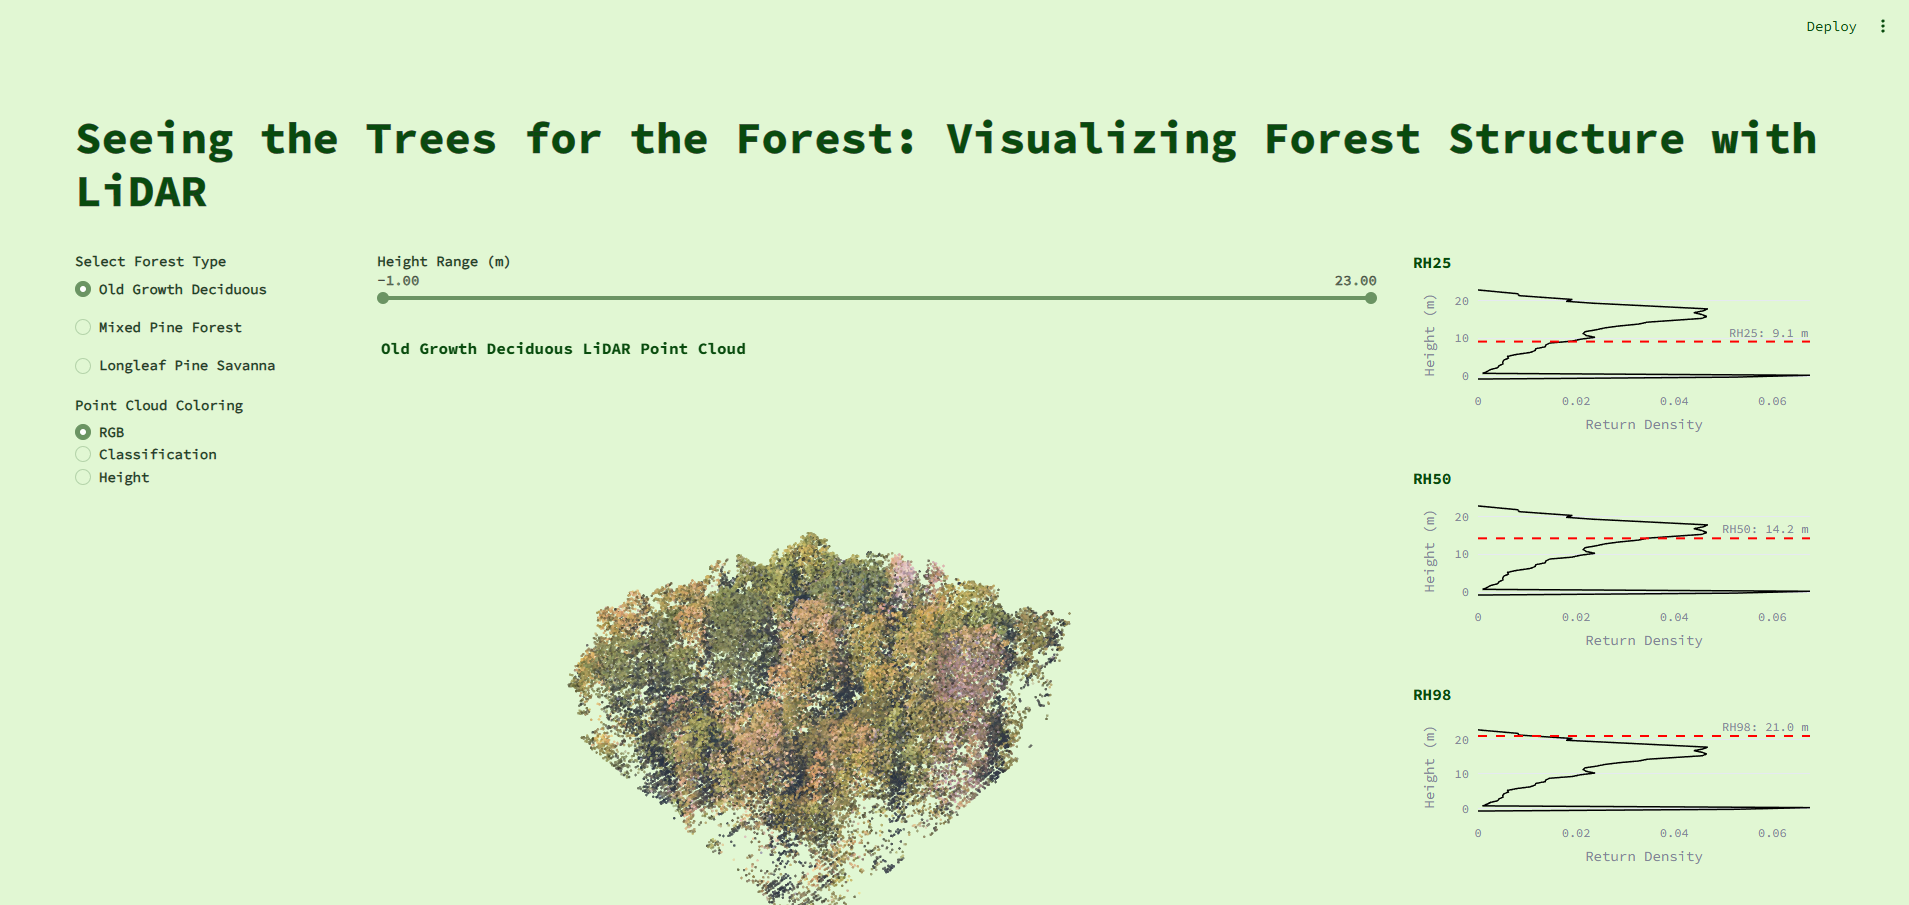

3. My interactive control chnages the forest type that the user can view, the point cloud color, he hieght range, and the user can rotate the point cloud around. This is useful to the user because it allows them to see how the metrics vary between forest types, chnage their visualization method to see how points are classed, how height varies, and the RGB color. 

4. I need to add a table of summary statistics so the users can more easily comparevbetween the forest types. 

**AI use disclosure**
I used ChatGPT for implementing interactive visualizations in streamlit. Google Gemini was also used when using a regular websearch, mostly for small code modifictions. While not AI, I also use stackoverflow extensively. A representative question is: 

"How can I add a height slider that filters the LiDAR point cloud?"

 ``       # Height range slider
    height_range = st.slider(
        "Height Range (m)",
        min_value=float(np.floor(z.min())),
        max_value=float(np.ceil(z.max())),
        value=(float(np.floor(z.min())), float(np.ceil(z.max()))),
        step=1.0
    )
    # Filter points by height
    height_mask = (z >= height_range[0]) & (z <= height_range[1])`` 

Once I added this slider, I had to go through and correct all my previously made RH plots so they used the height range determined by the slider. 



### 5.2 GitHub / reproducibility check — 2 points

Check your current repository. Some items may still be incomplete at this stage; the goal is to identify what is ready and what still needs work before the midterm.

| Item | Ready / Partial / Missing | What remains? |
|---|---|---|
| Main Streamlit app file | Ready | Just add the summary statistics |
| Data or data-access instructions | Partial | The data is available, but I need to add info on NEON.|
| Analysis notebook/scripts | Partial | Some of the analysis is done in R and I need to get all of that cleaned up and added. |
| README: project purpose | Missing | Full README needs written |
| README: setup/run instructions | Missing | Full README needs written |
| Key limitations documented | Missing | I need to write up limitations |
| AI-use disclosure | Missing | I need to add AI use disclosure |

**Repository link:** ...

If your repository is not yet fully organized, identify the **single most important reproducibility improvement** you will make next.

**Your response:**
I will add a readme next and info about the NEON data I am using. 

---
# Part 6 — Preliminary Midterm Presentation Slides (5 points)

Prepare a **4–6 slide preliminary deck** for your midterm presentation.

Submit the slides as a separate **PDF or PPTX** together with this homework.

Your slides should begin rehearsing the actual midterm presentation flow:

1. **Problem / audience / data**
2. **Important data-preparation or EDA decision**
3. **Preliminary key result(s)**
4. **Streamlit app / interaction**
5. **Limitation and remaining work**

You do not need one slide per item, and you may organize the story differently if it communicates your project more effectively.

### 6.1 Slide plan — 2 points

Complete a brief plan for your preliminary deck.

| Slide | Main message |
|---|---|
| 1 | Title page |
| 2 | Background on forest structure- why do we care?|
| 3 | Introduce LiDAR and main analytical question |
| 4 | Data preperation |
| 5 (optional) | App overview |
| 6 (optional) | results|

**Preliminary slide file name / link:** I submitted it to D2L with this notebook. 

### 6.2 Presentation self-check — 3 points

After creating the preliminary slides, answer:

1. What is the **single most important result** you currently plan to show?
2. What evidence supports it?
3. What slide currently feels weakest or least complete?
4. What would you remove if your presentation exceeds 7 minutes?
5. What question do you expect classmates or the instructor to ask?

**Your response:**

I plan to show a summary comparison of the RH values and how they vary between sites. The evidence that supports this are the KDE plots I am making to show the user. The results slide is probably the weakest, I need to create a table and nicer figures. I would remove some background and the slide that shows the app overview. I expect people to ask why this even matters, who even cares about these metrics, why would you choose these metrics, etc. 

---
# Part 7 — Midterm Rubric Gap Analysis and Work Plan (4 points)

Use the actual midterm expectations to identify remaining gaps.

Do not write “done” unless you can point to concrete evidence.

### 7.1 Rubric readiness table — 3 points

Use:

- **Ready** — evidence exists and is presentation-ready;
- **Partial** — meaningful progress exists but revision is needed;
- **Missing** — not yet implemented;
- **N/A** — genuinely not applicable, with justification.

| Midterm area | Current evidence | Status | Specific work remaining |
|---|---|---|---|
| Problem, audience & narrative | My question is well developed and I have all of the data to support the narrative. |Ready | N/A |
| Data quality & preparation | My data is cleaned, normalized, and cropped to a size where the app is functional. | Ready| N/A |
| EDA & visualization | My metric visualizations (KDE for R25,50,98) are all on the app.| Ready| N/A |
| Interpretation & limitations | I have my limitations and interpretations statements written out. |Partial | I need to add them to the GitHUb.|
| Streamlit data product | It's working, it has the interactive point clouds, it has the KDE plots, but I need to add a summary satistics table to it and deploy it. |Partial | Update the app for summary stats and deploy.|
| GitHub & reproducibility | The repo is online. |Partial | I need to get all my scripts uploaded and get the documentation together. |

### 7.2 Priority work before the midterm — 1 point

List your **three highest-priority tasks**, in order.

For each task, make it concrete enough that you will know when it is complete.

1. Update streamlit app with summary statistics and deploy.
2. Put together GitHub repo with analysis scripts and proper documentation.
3. Update results slide.

Then finish this sentence:

> **The biggest risk to having a presentation-ready project is not having robust enough analysis involved on my app.**

---
# Final Readiness Reflection

In 3–5 sentences:

- What part of your project is currently strongest?
- What part needs the most work?
- What did this homework reveal that a simple “progress report” would not have revealed?

**Your response:**

I think my app is the strongest part so far. It is basically finished on the backend, withg only minor cosmetic updates and adding the summary table. My GitHub repo is definitely the weakest; I don't have anything on there except the app and the data. This homework made me think through all of my design and analysis decisions and scrutinize why I chose them. It revealed gaps in my thinking that will likely need revised before the final. It also recapped all of the topics we've covered and reminded me of options for revising for the final. 

In [59]:
import numpy as np 
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# create arrays from input data and coefficents 
X_input = np.array([
    [1, 1, 4, 2, 1, 5],
    [1, 2, 3, 1, 2, 4],
    [1, 3, 2, 2, 4, 3]
])

# model weights
coefs = np.array([0.0, 0.1, 0.2,
0.5, 2, 0.2])

# intercept
bias = 0

# actual values 
actual_vals = np.array([5, 4.9, 10.5])

# set up our model
model = LinearRegression()
model.coef_ = coefs
model.intercept_ = bias

# predict
predictions = model.predict(X_input)
print("Model predictions:", predictions)

# lets use the dot product instead now 
dot_preds = np.dot(X_input, coefs)
print("Dot product:", dot_preds)

# now lets look at our mean squared errorn 
mse = mean_squared_error(actual_vals, predictions)
print("Mean squared error:", mse)

Model predictions: [ 4.9  6.1 10.3]
Dot product: [ 4.9  6.1 10.3]
Mean squared error: 0.4966666666666661


---
# AI Use Disclosure

If you used generative AI during Homework 05, report:

- **Tool/version:** No AI was used for this homeworks analysis, other than where it was specififed for app development.
- **Purpose(s) or representative prompt(s):**
- **How you checked the output:**
- **Your own analytical contribution / decisions:**

If you did not use AI, write:

> **No AI used.**

---
# Submission Checklist

Before submitting Homework 05, confirm that you have:

- [ ] completed the 150–200 word project abstract;
- [ ] stated the project question, user, and scope;
- [ ] documented data source, observation unit, variables, and data quality;
- [ ] justified your missing-data decision;
- [ ] answered two project-specific analytical questions with visual and quantitative evidence;
- [ ] evaluated the design of your most important visualization;
- [ ] completed the course-concept relevance audit;
- [ ] applied two relevant course concepts;
- [ ] justified one concept you intentionally did not apply;
- [ ] documented current Streamlit progress;
- [ ] completed the GitHub/reproducibility check;
- [ ] prepared and submitted 4–6 preliminary midterm slides;
- [ ] completed the midterm rubric gap analysis;
- [ ] listed three concrete priorities before the midterm;
- [ ] completed the final readiness reflection;
- [ ] included visible code outputs;
- [ ] included an AI-use disclosure.

### Submit

1. your completed Homework 05 `.ipynb` notebook; and  
2. your preliminary midterm slide deck (`.pdf` or `.pptx`).